# Histology-guided deconvolution: HER2ST G2

**Author: Su Xu**

Combine RNA with registered H&E morphology. G2 contains **467 spots, 14,898 genes and six pathological regions**; only the **402 labelled spots** enter quantitative evaluation. Both arms start from the same count-only consensus. The H&E arm adds morphology reconstruction and morphology-gated spatial smoothing.

HIPT and UNI encode image appearance independently of RNA and pathology labels. Each encoder's spatial features are reduced by PCA to 99% cumulative variance, quantized into 16 visual words, and pooled over each capture footprint. Concatenating the two frequency vectors with equal half-mass gives $Q\in\mathbb{R}^{N\times32}$. The model jointly learns RNA profiles $B$, morphology profiles $H$ and shared weights $P$, minimizing RNA KL + weighted morphology KL + graph TV. Both morphology reconstruction and TV use exposure weighting. Morphology differences reduce smoothing across image boundaries.

## 1. Set up

Install spDecon using the repository installation instructions, then run this notebook from the cloned repository. The first data-loading cell downloads the versioned data bundle if needed. Saved fits make all plots available on a CPU. Full reference-free training uses the pinned CUDA environment. The saved results are complete fits, not shortened runs. `RUN_FIT=True` executes the full fitting code below; deterministic kernels and a fixed seed support repeatable new fits. Small differences from historical GPU runs may remain.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tutorials.common import dataset, correlation, align, spatial, pies, legend, save_figure, save_table
from spDecon.reproducibility import set_seed
set_seed(0, deterministic=True)
# The published outputs inspect complete fitted results. Enable full training explicitly.
RUN_FIT = False


## 2. Load the registered image inputs and molecular data

`image_spots.csv` contains spot centers in original image pixels, with x horizontal and y vertical. Image resolution and spot radius accompany the original H&E. The supplied `Q` was regenerated from this H&E image with the extraction code below and agrees with the archived morphology matrix.

In [2]:
path,data=dataset("g2")
y=np.array(data["Y"],dtype=float,order="F")
xy,q=data["coordinates"],data["Q"]
image_spots=pd.read_csv(path/"image_spots.csv",index_col=0)
print("Counts:",y.shape,"Morphology:",q.shape)
print("Microns/pixel:",(path/"microns_per_pixel.txt").read_text().strip())
print("Spot radius, pixels:",(path/"radius_pixels.txt").read_text().strip())

Counts: (467, 14898) Morphology: (467, 32)
Microns/pixel: 0.6878475741620447
Spot radius, pixels: 72.69052313066803


## 3. Extract HIPT and UNI feature embeddings

Install the optional `requirements-histology.lock.txt` environment. Clone [spEnhance](https://github.com/dsong-lab/spEnhance); its encoder scripts are in the repository root. Obtain the two HIPT checkpoints `vit256_small_dino.pth` and `vit4k_xs_dino.pth` from the [official HIPT release](https://github.com/mahmoodlab/HIPT), placing them under that directory's `checkpoints/`. Request access to [MahmoodLab/UNI](https://huggingface.co/MahmoodLab/UNI) and log in locally with `hf auth login`. Model weights are obtained by each user under their original terms.

The adapter rescales the registered image to 0.5 μm/pixel, runs shifted HIPT and UNI feature extraction, then performs PCA, dictionary fitting and spot pooling. It writes intermediate embeddings, PCA transforms, visual-word dictionaries and `morphology.npz`. A new output directory is required. Extraction is optional here because the complete derived features are supplied; it uses a GPU and more memory than displaying the saved figures.

```bash
git clone https://github.com/dsong-lab/spEnhance.git external/spEnhance
```


In [3]:
from spDecon.image_features import extract_histology
EXTRACT_IMAGE = False
if EXTRACT_IMAGE:
    q_frame=extract_histology(
        path/"he.jpg",image_spots,
        microns_per_pixel=float((path/"microns_per_pixel.txt").read_text()),
        radius_pixels=float((path/"radius_pixels.txt").read_text()),
        encoder_source=ROOT/"external/spEnhance",
        output=ROOT/"outputs/g2_features",device="cuda")
    q=q_frame.loc[data["spots"]].to_numpy()
print("Each encoder block sums to:",q.reshape(len(q),2,16).sum(axis=2).mean(axis=0))

Each encoder block sums to: [0.5 0.5]


## 4. Fit the paired RNA-only and RNA + H&E models

The G2 coefficients are frozen at image weight 0.0331071274524168 and spatial weight 0.012495695149619745. For new data, omitting these arguments invokes gradient calibration. Both arms use the same initialization, genes and spots. Pathology labels are used only in the next step.

In [4]:
from spDecon.consensus import build_consensus
from spDecon.histology import fit_histology
cal=json.loads((path/"calibration.json").read_text())
fits={}
if RUN_FIT:
    initial=build_consensus(y,6,random_state=0)
    for arm in ["RNA_TV","RNA_HE_TV"]:
        result=fit_histology(y,q if arm=="RNA_HE_TV" else None,xy,6,
            image_weight=cal["image_weight"] if arm=="RNA_HE_TV" else 0.,
            spatial_weight=cal["spatial_weight"],initial_proportions=initial.consensus_proportions,
            initial_profiles=initial.consensus_profiles,random_state=0,device="cuda",max_iter=20000)
        fits[arm]=result.proportions
        print(arm,result.diagnostics)
else:
    fits={arm:np.load(path/(arm+".npz"))["P"] for arm in ["RNA_TV","RNA_HE_TV"]}

/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: Futur

## 5. Compare pathological structure on the fixed support

PCC compares aligned component weights with one-hot region labels. ARI compares dominant-component assignments with pathology. Boundary F1 compares edges crossing predicted versus true region boundaries, restricting both ends to the 402-spot support. The quantitative display follows the idea of Figure 3B, using G2 rather than its Normal1 dataset; the maps correspond to the G2 comparison in Figure 3F.

,model,PCC,ARI,Boundary F1,n
0,RNA_TV,0.447552,0.2472,0.428571,402
1,RNA_HE_TV,0.541291,0.3816,0.474438,402


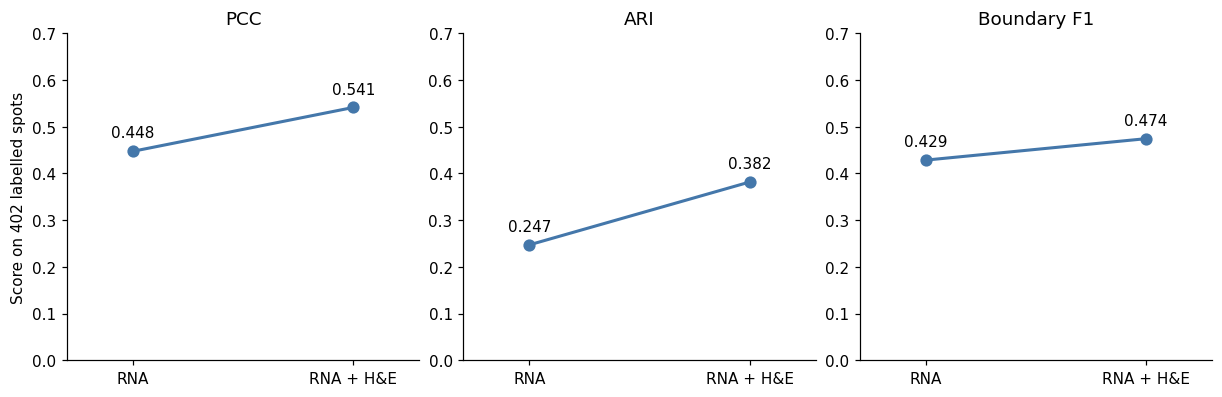

In [5]:
from sklearn.metrics import adjusted_rand_score,f1_score
support=pd.Index(data["spots"]).get_indexer(data["support"])
labels=np.sort(np.unique(data["annotations"][support]))
codes=pd.Categorical(data["annotations"][support],categories=labels).codes
truth=np.eye(len(labels))[codes]
position=np.full(len(y),-1);position[support]=np.arange(len(support))
ii,jj=position[data["edge_i"]],position[data["edge_j"]]
keep=(ii>=0)&(jj>=0);ii,jj=ii[keep],jj[keep]
rows=[];mapped={}
for arm,p in fits.items():
    matched,order=align(p[support],truth)
    mapped[arm]=p[:,order]
    pred=matched.argmax(axis=1)
    rows.append({"model":arm,"PCC":np.diag(correlation(matched,truth)).mean(),
                 "ARI":adjusted_rand_score(codes,pred),
                 "Boundary F1":f1_score(codes[ii]!=codes[jj],pred[ii]!=pred[jj]),"n":len(support)})
scores=pd.DataFrame(rows)
display(save_table(scores,"g2_paired_metrics"))
fig,axes=plt.subplots(1,3,figsize=(11,3.5),layout="constrained")
for ax,metric in zip(axes,["PCC","ARI","Boundary F1"]):
    values=scores[metric].to_numpy()
    ax.plot([0,1],values,"o-",color="#4477AA",lw=2,ms=7)
    for j,value in enumerate(values):ax.annotate(f"{value:.3f}",(j,value),xytext=(0,9),textcoords="offset points",ha="center")
    ax.set(xticks=[0,1],xticklabels=["RNA","RNA + H&E"],ylim=(0,.7),xlim=(-.3,1.3),title=metric)
axes[0].set_ylabel("Score on 402 labelled spots")
save_figure(fig,"g2_improvement")

## 6. Display region maps

Component colors are aligned separately to pathology for interpretation. Unlabelled spots remain in both fits and appear grey only in the truth panel. This one-section comparison does not provide biological replicate uncertainty.

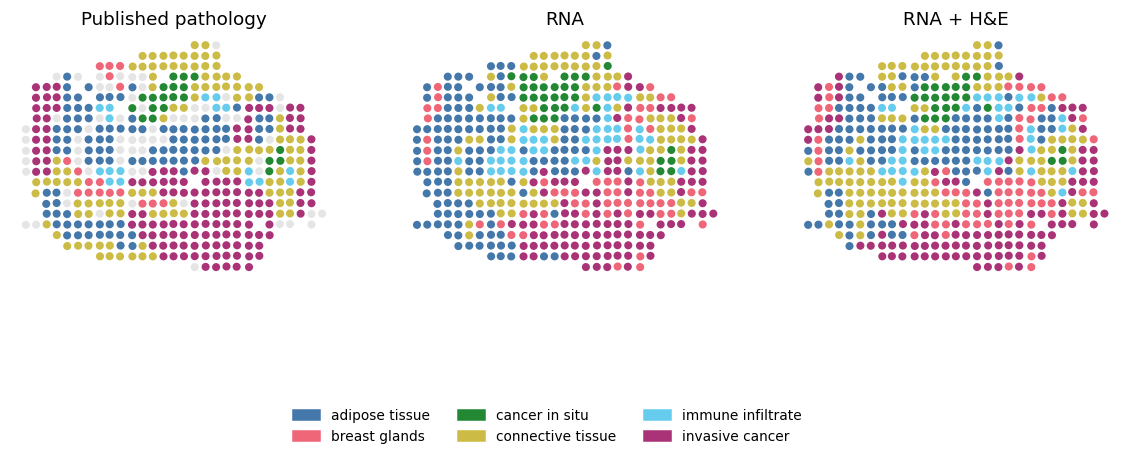

In [6]:
fig,axes=plt.subplots(1,3,figsize=(13,5))
full_codes=np.full(len(y),-1);full_codes[support]=codes
spatial(axes[0],xy,full_codes,"Published pathology",categorical=True,size=28)
for ax,(arm,p) in zip(axes[1:],mapped.items()):
    spatial(ax,xy,p.argmax(axis=1),"RNA" if arm=="RNA_TV" else "RNA + H&E",categorical=True,size=28)
legend(fig,labels,columns=3,y=-.025)
fig.subplots_adjust(bottom=.16)
save_figure(fig,"g2_regions")